In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers
import matplotlib.pyplot as plt

**load data**

In [ ]:
(train_images, _), (_, _) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


**training**

In [ ]:
# Reload to ensure clean state
(train_images, _), (_, _) = tf.keras.datasets.mnist.load_data()

train_images = train_images.astype("float32")
train_images = (train_images - 127.5) / 127.5
train_images = np.expand_dims(train_images, axis=-1)

BATCH_SIZE = 128
NOISE_DIM = 100
EPOCHS = 30

train_datasets = (tf.data.Dataset.from_tensor_slices(train_images)
.shuffle(60000)
.batch(BATCH_SIZE))

print("shape", train_images.shape)

shape (60000, 28, 28, 1)


**create a generator**

In [ ]:
def make_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
    ])
    return model

generator = make_generator()
generator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

**disciminator**

In [ ]:
def make_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

discriminator = make_discriminator()
discriminator.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

**loss functions and optimizations**

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

**train  the GAN**

In [ ]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = generator_loss(fake_output)
        d_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )
    disc_gradients = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss


for epoch in range(EPOCHS):
    g_losses = []
    d_losses = []

    for real_images in train_datasets:
        g_loss, d_loss = train_step(real_images)
        g_losses.append(float(g_loss))
        d_losses.append(float(d_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS}, "
        f"G Loss: {np.mean(g_losses):.4f}, "
        f"D Loss: {np.mean(d_losses):.4f}"
    )

Epoch 1/30, G Loss: 1.3126, D Loss: 0.6975
Epoch 2/30, G Loss: 1.0815, D Loss: 0.9923
Epoch 3/30, G Loss: 1.0250, D Loss: 1.1628
Epoch 4/30, G Loss: 0.9758, D Loss: 1.2103
Epoch 5/30, G Loss: 0.9515, D Loss: 1.2277
Epoch 6/30, G Loss: 0.9690, D Loss: 1.1917
Epoch 7/30, G Loss: 0.9915, D Loss: 1.2007
Epoch 8/30, G Loss: 1.0128, D Loss: 1.1422
Epoch 9/30, G Loss: 1.0775, D Loss: 1.0987
Epoch 10/30, G Loss: 1.1613, D Loss: 1.0490
Epoch 11/30, G Loss: 1.1870, D Loss: 1.0615
Epoch 12/30, G Loss: 1.1796, D Loss: 1.0482
Epoch 13/30, G Loss: 1.1507, D Loss: 1.0678
Epoch 14/30, G Loss: 1.1869, D Loss: 1.0745
Epoch 15/30, G Loss: 1.2135, D Loss: 1.0517
Epoch 16/30, G Loss: 1.1657, D Loss: 1.0853
Epoch 17/30, G Loss: 1.1279, D Loss: 1.1166
Epoch 18/30, G Loss: 1.1226, D Loss: 1.1215
Epoch 19/30, G Loss: 1.0773, D Loss: 1.1410
Epoch 20/30, G Loss: 1.0593, D Loss: 1.1536
Epoch 21/30, G Loss: 1.0674, D Loss: 1.1584
Epoch 22/30, G Loss: 1.0421, D Loss: 1.1658
Epoch 23/30, G Loss: 1.0096, D Loss: 1.17

Minimum: -1.0
Maximum: 0.99999654
Mean: -0.7416258
Standard deviation: 0.6144887


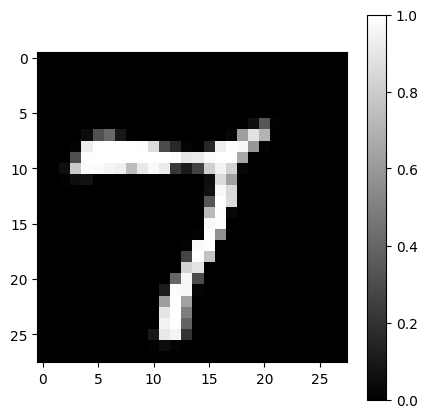

In [ ]:
noise = tf.random.normal([16, NOISE_DIM])
generated_images = generator(noise, training=False)

print("Minimum:", tf.reduce_min(generated_images).numpy())
print("Maximum:", tf.reduce_max(generated_images).numpy())
print("Mean:", tf.reduce_mean(generated_images).numpy())
print("Standard deviation:", tf.math.reduce_std(generated_images).numpy())

plt.figure(figsize=(5, 5))
plt.imshow(
    (generated_images[0, :, :, 0].numpy() + 1) / 2,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.colorbar()
plt.show()

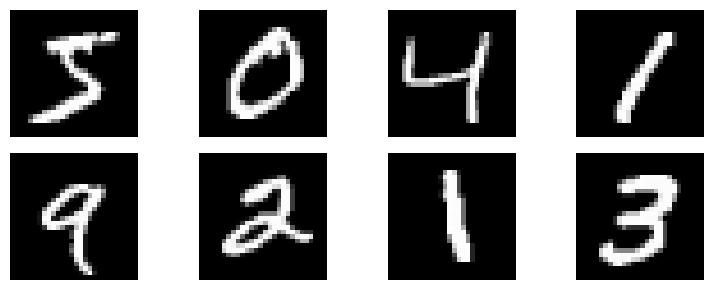

In [ ]:
plt.figure(figsize=(8, 3))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(train_images[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

**generate handwritten digits**

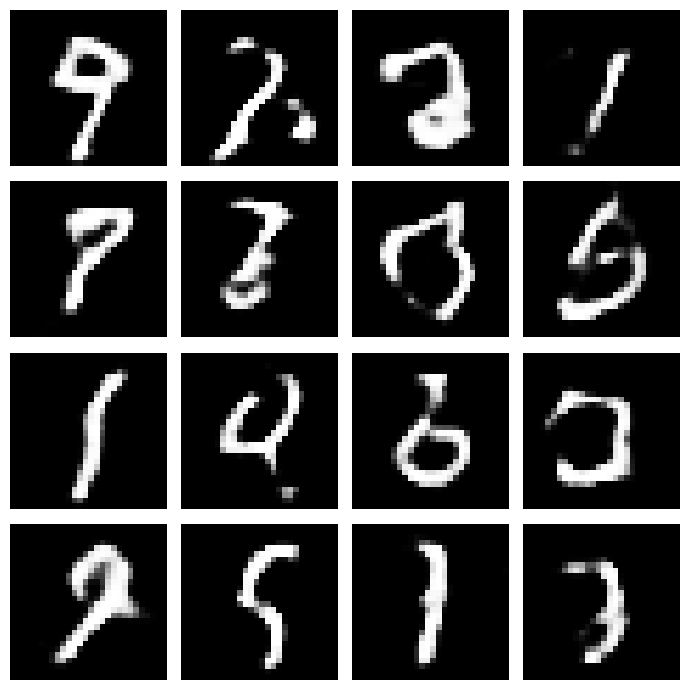

In [ ]:
noise = tf.random.normal([16, NOISE_DIM])
generated_images = generator(noise, training=False)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):
    image = (generated_images[i, :, :, 0].numpy() + 1) / 2
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

**new**

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (60000, 28, 28, 1)
Pixel range: -1.0 1.0


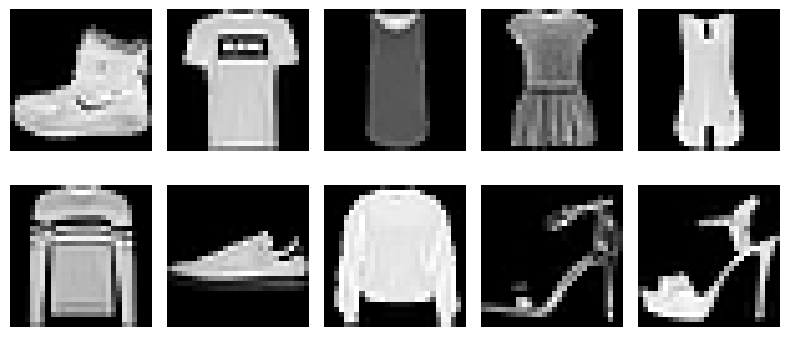

In [63]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Dataset shape:", x_train.shape)
print("Pixel range:", x_train.min(), x_train.max())

plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [64]:

from tensorflow.keras import layers, Model

latent_dim = 100

generator = tf.keras.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(7 * 7 * 128),
    layers.Reshape((7, 7, 128)),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(64, 4, strides=2, padding="same"),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
])

discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Conv2D(128, 4, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1)
])

generator.summary()
discriminator.summary()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_6 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_27 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_28 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_12             │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 766,401 (2.92 MB)

 Trainable params: 766,017 (2.92 MB)

 Non-trainable params: 384 (1.50 KB)

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_29 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_30 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:

batch_size = 128
epochs = 15

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([batch_size, latent_dim])

    with tf.GradientTape() as d_tape, tf.GradientTape() as g_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        d_loss = bce(tf.ones_like(real_output), real_output)
        d_loss += bce(tf.zeros_like(fake_output), fake_output)

        g_loss = bce(tf.ones_like(fake_output), fake_output)

    d_gradients = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_gradients = g_tape.gradient(g_loss, generator.trainable_variables)

    d_optimizer.apply_gradients(zip(d_gradients, discriminator.trainable_variables))
    g_optimizer.apply_gradients(zip(g_gradients, generator.trainable_variables))

    return d_loss, g_loss

for epoch in range(epochs):
    d_losses = []
    g_losses = []

    for images in dataset:
        d_loss, g_loss = train_step(images)
        d_losses.append(d_loss)
        g_losses.append(g_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"D Loss: {tf.reduce_mean(d_losses):.4f} | "
        f"G Loss: {tf.reduce_mean(g_losses):.4f}"
    )


Epoch 1/15 | D Loss: 1.2977 | G Loss: 0.7305
Epoch 2/15 | D Loss: 1.1217 | G Loss: 0.9436
Epoch 3/15 | D Loss: 0.9789 | G Loss: 1.1512
Epoch 4/15 | D Loss: 1.0645 | G Loss: 1.0915
Epoch 5/15 | D Loss: 1.1573 | G Loss: 0.9855
Epoch 6/15 | D Loss: 1.2015 | G Loss: 0.9244
Epoch 7/15 | D Loss: 1.2270 | G Loss: 0.8921
Epoch 8/15 | D Loss: 1.2514 | G Loss: 0.8635
Epoch 9/15 | D Loss: 1.2574 | G Loss: 0.8520
Epoch 10/15 | D Loss: 1.2668 | G Loss: 0.8398
Epoch 11/15 | D Loss: 1.2696 | G Loss: 0.8363
Epoch 12/15 | D Loss: 1.2665 | G Loss: 0.8375
Epoch 13/15 | D Loss: 1.2683 | G Loss: 0.8369
Epoch 14/15 | D Loss: 1.2711 | G Loss: 0.8361
Epoch 15/15 | D Loss: 1.2726 | G Loss: 0.8345


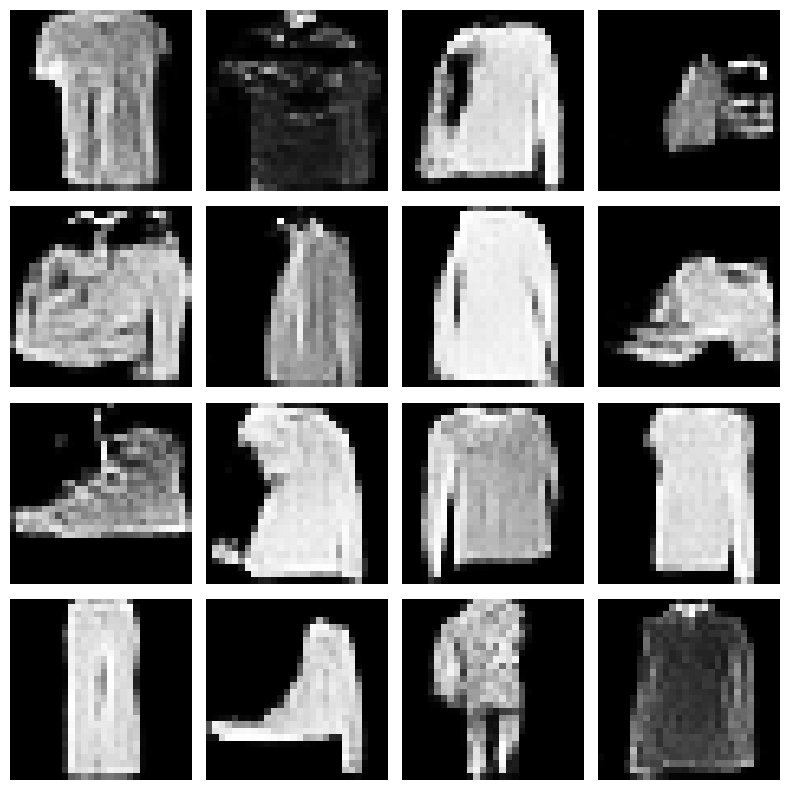

In [67]:

noise = tf.random.normal([16, latent_dim])
generated_images = generator(noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i, :, :, 0] * 0.5 + 0.5, cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


**speech recognition**

In [69]:
!pip -q install tensorflow-datasets importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds

(ds_train, ds_test), info = tfds.load(
    "speech_commands",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print("Training examples:", info.splits["train"].num_examples)
print("Testing examples:", info.splits["test"].num_examples)
print("Dataset loaded successfully!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


...

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/speech_commands/incomplete.5Q3RSO_0.0.3/speech_commands-validation.tfrecor…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/speech_commands/incomplete.5Q3RSO_0.0.3/speech_commands-test.tfrecord-[0-9…

Dataset speech_commands downloaded and prepared to /root/tensorflow_datasets/speech_commands/0.0.3. Subsequent calls will reuse this data.
Training examples: 85511
Testing examples: 4890
Dataset loaded successfully!


In [70]:

import matplotlib.pyplot as plt
from IPython.display import Audio, display

audio, label = next(iter(ds_train.take(1)))

print("Audio shape:", audio.shape)
print("Sample rate: 16,000 Hz")

display(Audio(audio.numpy().squeeze(), rate=16000))


Audio shape: (16000,)
Sample rate: 16,000 Hz


In [71]:

import numpy as np
import tensorflow as tf

SAMPLE_RATE = 16000
AUDIO_LENGTH = 16000
NUM_MFCC = 40

class_names = info.features["label"].names
print("Available labels:", class_names)

def preprocess_audio(audio, label):
    audio = tf.cast(audio, tf.float32)
    audio = tf.squeeze(audio)

    audio = audio[:AUDIO_LENGTH]
    audio = tf.pad(audio, [[0, tf.maximum(0, AUDIO_LENGTH - tf.shape(audio)[0])]])

    stft = tf.signal.stft(
        audio,
        frame_length=400,
        frame_step=160,
        fft_length=512
    )

    spectrogram = tf.abs(stft)
    mel_matrix = tf.signal.linear_to_mel_weight_matrix(
        num_mel_bins=NUM_MFCC,
        num_spectrogram_bins=257,
        sample_rate=SAMPLE_RATE,
        lower_edge_hertz=80.0,
        upper_edge_hertz=7600.0
    )

    mel_spectrogram = tf.matmul(spectrogram, mel_matrix)
    log_mel = tf.math.log(mel_spectrogram + 1e-6)

    return log_mel, label

train_data = ds_train.map(
    preprocess_audio,
    num_parallel_calls=tf.data.AUTOTUNE
).shuffle(5000).batch(64).prefetch(tf.data.AUTOTUNE)

test_data = ds_test.map(
    preprocess_audio,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(64).prefetch(tf.data.AUTOTUNE)

for features, labels in train_data.take(1):
    print("Feature batch shape:", features.shape)
    print("Label batch shape:", labels.shape)


Available labels: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes', '_silence_', '_unknown_']
Feature batch shape: (64, 98, 40)
Label batch shape: (64,)


In [72]:

from tensorflow.keras import layers, models

num_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(None, NUM_MFCC)),
    layers.Normalization(axis=-1),
    layers.Conv1D(64, 5, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(128, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

normalizer = model.layers[0]
normalizer.adapt(train_data.map(lambda x, y: x))

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, None, 40)       │            81 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, None, 64)       │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, None, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, None, 128)      │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,685 (182.37 KB)

 Trainable params: 46,604 (182.05 KB)

 Non-trainable params: 81 (328.00 B)

In [73]:

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=5
)


Epoch 1/5
1337/1337 ━━━━━━━━━━━━━━━━━━━━ 105s 70ms/step - accuracy: 0.6989 - loss: 1.0322 - val_accuracy: 0.6311 - val_loss: 1.1205
Epoch 2/5
1337/1337 ━━━━━━━━━━━━━━━━━━━━ 92s 62ms/step - accuracy: 0.8314 - loss: 0.5356 - val_accuracy: 0.7470 - val_loss: 0.7807
Epoch 3/5
1337/1337 ━━━━━━━━━━━━━━━━━━━━ 91s 65ms/step - accuracy: 0.8674 - loss: 0.4215 - val_accuracy: 0.7798 - val_loss: 0.7042
Epoch 4/5
1337/1337 ━━━━━━━━━━━━━━━━━━━━ 91s 64ms/step - accuracy: 0.8883 - loss: 0.3612 - val_accuracy: 0.8292 - val_loss: 0.5701
Epoch 5/5
1337/1337 ━━━━━━━━━━━━━━━━━━━━ 89s 63ms/step - accuracy: 0.9013 - loss: 0.3152 - val_accuracy: 0.8311 - val_loss: 0.5389


In [74]:

audio, true_label = next(iter(ds_test.take(1)))

features, _ = preprocess_audio(audio, true_label)
prediction = model.predict(features[None, ...], verbose=0)

predicted_label = class_names[np.argmax(prediction[0])]

print("Actual word:", class_names[int(true_label)])
print("Predicted word:", predicted_label)
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")


Actual word: stop
Predicted word: stop
Confidence: 81.54 %
